# Chapitre 14 - Exercices 14.13 à 14.17

Ce notebook traite cinq exercices consacrés aux méthodes de **réduction de dimension
non linéaires ou latentes** du chapitre 14 :

- **14.13** : courbe principale et carte auto-organisatrice (SOM) sur une hélice ;
- **14.14** : analyse factorielle et matrice de corrélation ;
- **14.15** : ACP contre analyse factorielle sur un exemple de G. Hinton ;
- **14.16** : ACP à noyau, rang et projection de nouvelles observations ;
- **14.17** : ACP à noyau vue comme un problème d'optimisation fonctionnelle.

Les fonctions réutilisables sont dans le module `esl/ch14_non_supervise_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch14_non_supervise_complements as nsc
set_style()

## Exercice 14.13 : Courbe principale et SOM pour une hélice

**Énoncé (reformulé).** On simule $N=200$ points de $\mathbb{R}^3$ proches d'une hélice :
$$X_1 = \cos(s) + 0{,}1\,Z_1,\qquad X_2 = \sin(s) + 0{,}1\,Z_2,\qquad X_3 = s + 0{,}1\,Z_3,$$
où $s$ parcourt 200 valeurs régulièrement espacées de $[0, 2\pi]$ et $Z_1, Z_2, Z_3$ sont
des gaussiennes centrées réduites indépendantes.

(a) Ajuster une **courbe principale** et tracer les fonctions coordonnées estimées ;
les comparer à $\cos(s)$, $\sin(s)$ et $s$.

(b) Ajuster une **carte auto-organisatrice** (SOM) aux mêmes données et voir si elle
retrouve la forme hélicoïdale du nuage.

### Rappel : courbe principale (section 14.5.2 du livre)

Une courbe paramétrée $f(\lambda) = (f_1(\lambda), \dots, f_p(\lambda))$ est une **courbe
principale** de la loi de $X$ si elle est *auto-cohérente* (éq. (14.61) du livre) :
$$f(\lambda) = \mathbb{E}\big[X \,\big|\, \lambda_f(X) = \lambda\big],$$
où $\lambda_f(x)$ est le paramètre du point de la courbe le plus proche de $x$.
Autrement dit, chaque point de la courbe est la moyenne des points qui se projettent sur lui.

> **Intuition.** C'est l'analogue « courbe » de la première composante principale :
> la droite de l'ACP est la droite auto-cohérente pour une loi gaussienne.

### L'algorithme alterné (14.62)

Avec des données, on part de la première composante principale (le paramètre $\lambda_i$
est la coordonnée de $x_i$ sur cette droite), puis on alterne :

- **(a) lissage** : pour chaque coordonnée $j$, on estime $\hat f_j(\lambda) \approx
  \mathbb{E}(X_j \mid \lambda)$ en lissant les $x_{ij}$ en fonction des $\hat\lambda_i$
  (nous utilisons une régression linéaire locale à noyau gaussien) ;
- **(b) projection** : chaque $x_i$ est projeté sur la courbe $\hat f$, ce qui donne
  un nouveau $\hat\lambda_i$ égal à l'**abscisse curviligne** (longueur d'arc depuis
  l'origine de la courbe) du point le plus proche.

La somme des distances au carré $\sum_i \|x_i - \hat f(\hat\lambda_i)\|^2$ sert de critère
de suivi.

In [2]:
rng = np.random.RandomState(0)
N = 200
s = np.linspace(0, 2 * np.pi, N)
X = np.column_stack([np.cos(s), np.sin(s), s]) + 0.1 * rng.randn(N, 3)
X[:3].round(3)

array([[ 1.176,  0.04 ,  0.098],
       [ 1.224,  0.218, -0.066],
       [ 1.093,  0.048,  0.053]])

Visualisons le nuage en trois dimensions : l'hélice fait un tour complet autour de l'axe
$X_3$.

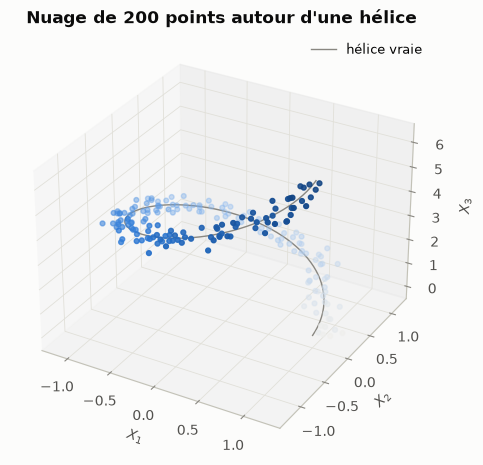

In [3]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=s, cmap=SEQ, s=12)
ax.plot(np.cos(s), np.sin(s), s, color=GRAY, lw=1, label="hélice vraie")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("Nuage de 200 points autour d'une hélice")
ax.legend()
plt.show()

### (a) Ajustement de la courbe principale

On lance 15 itérations de l'algorithme. La largeur du noyau vaut 8 % de la longueur de la
courbe : assez petite pour suivre les oscillations de $\cos$ et $\sin$, assez grande pour
lisser le bruit.

In [4]:
pc = nsc.principal_curve(X, n_iter=15, bandwidth_frac=0.08)
pc["history"].round(3)

array([5.795, 5.799, 5.803, 5.801, 5.798, 5.796, 5.795, 5.793, 5.792,
       5.791, 5.79 , 5.789, 5.789, 5.788, 5.788])

Le critère décroît légèrement puis se stabilise : l'initialisation par la première
composante principale (dirigée selon $X_3$, l'axe de l'hélice) est déjà bonne pour la
projection, et les itérations ajustent la courbe.

### Comparaison des fonctions coordonnées

La courbe est paramétrée par l'abscisse curviligne $\lambda$, qui n'est définie qu'à une
**reparamétrisation près** (origine, sens de parcours, échelle). Pour l'hélice vraie,
la vitesse est $\|(-\sin s, \cos s, 1)\| = \sqrt 2$, donc $\lambda = \sqrt2\, s$.
Comme la courbe estimée est un peu raccourcie aux extrémités (effet de bord du lisseur),
nous ramenons simplement $\lambda$ sur $[0, 2\pi]$ par une transformation affine, en
choisissant le sens de parcours qui suit $s$.

In [5]:
lam, F, grid = pc["lam"], pc["curve"], pc["grid"]
if np.corrcoef(lam, s)[0, 1] < 0:          # sens de parcours
    lam, grid = grid[-1] - lam, grid[-1] - grid
s_hat = 2 * np.pi * (lam - grid.min()) / (grid.max() - grid.min())
s_grid = 2 * np.pi * (grid - grid.min()) / (grid.max() - grid.min())
print("corrélation entre s et le paramètre estimé : %.4f" % np.corrcoef(s, s_hat)[0, 1])

corrélation entre s et le paramètre estimé : 0.9992


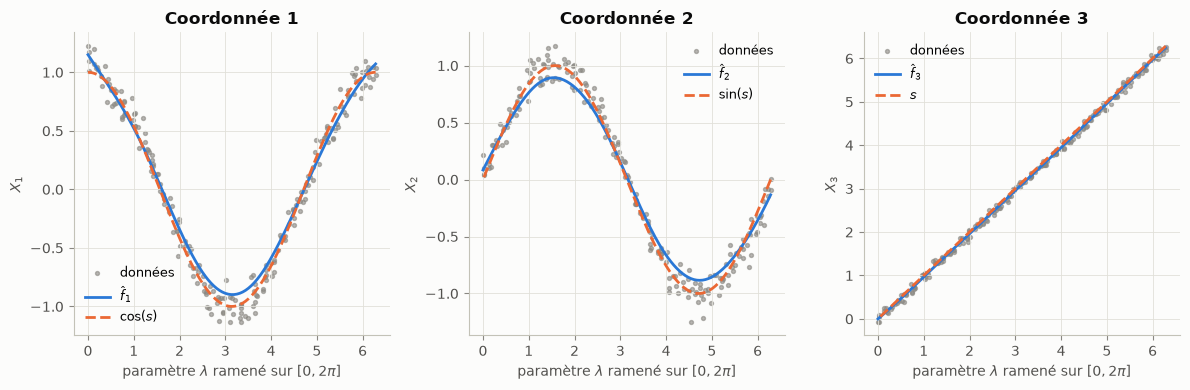

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
truth = [np.cos, np.sin, lambda u: u]
names = [r"$\cos(s)$", r"$\sin(s)$", r"$s$"]
for j, ax in enumerate(axes):
    ax.scatter(s_hat, X[:, j], s=8, color=GRAY, alpha=0.6, label="données")
    ax.plot(s_grid, F[:, j], color=BLUE, label=r"$\hat f_%d$" % (j + 1))
    ax.plot(s_grid, truth[j](s_grid), color=ORANGE, ls="--", label=names[j])
    ax.set_xlabel(r"paramètre $\lambda$ ramené sur $[0, 2\pi]$")
    ax.set_ylabel("$X_%d$" % (j + 1))
    ax.set_title("Coordonnée %d" % (j + 1))
    ax.legend()
plt.tight_layout()
plt.show()

Les trois fonctions coordonnées estimées suivent de très près $\cos(s)$, $\sin(s)$ et $s$.
On observe un léger **aplatissement aux extrémités** et aux extrema de $\cos$/$\sin$ :
c'est le biais classique d'un lisseur, qui moyenne des points situés de part et d'autre
d'un sommet.

Vue 3D de la courbe principale obtenue :

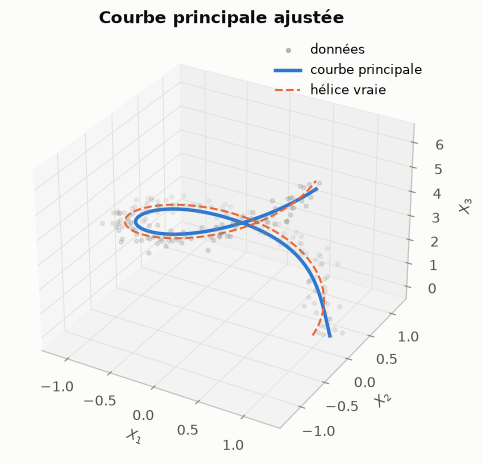

In [7]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], color=GRAY, s=8, alpha=0.5, label="données")
ax.plot(F[:, 0], F[:, 1], F[:, 2], color=BLUE, lw=2.5, label="courbe principale")
ax.plot(np.cos(s), np.sin(s), s, color=ORANGE, ls="--", lw=1.5, label="hélice vraie")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("Courbe principale ajustée")
ax.legend()
plt.show()